# 01 — Exploratory data analysis (CirCor DigiScope, public part)

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, soundfile as sf, librosa, librosa.display
from src.data import load_patients, load_recordings, load_split, WAV_DIR
from src.metrics import weighted_accuracy
pd.set_option('display.width', 140)

## Patients and labels

In [2]:
pat = load_patients()
print(len(pat), 'patients')
pat['Murmur'].value_counts().to_frame().assign(pct=lambda d: (100*d['count']/d['count'].sum()).round(1))

942 patients


,count,pct
Murmur,,
Absent,695,73.8
Present,179,19.0
Unknown,68,7.2


In [3]:
# Baseline: always predicting one class
for c in ['Absent', 'Present', 'Unknown']:
    print(f'always {c:8s} WA = {weighted_accuracy(pat.Murmur, [c]*len(pat)):.3f}')

always Absent   WA = 0.387
always Present  WA = 0.499
always Unknown  WA = 0.114


In [4]:
pd.crosstab(pat['Age'].fillna('NA'), pat['Murmur'])

Murmur,Absent,Present,Unknown
Age,,,
Adolescent,53,16,3
Child,495,132,37
Infant,76,25,25
NA,67,5,2
Neonate,4,1,1


## Recordings

In [5]:
rec = load_recordings()
info = [sf.info(p) for p in rec.path]
rec['sr'] = [i.samplerate for i in info]
rec['duration'] = [i.duration for i in info]
print(len(rec), 'recordings;', rec.patient_id.nunique(), 'patients; sample rates:', rec.sr.unique())
rec.groupby('patient_id').size().value_counts().sort_index().rename('patients with n recordings')

3163 recordings; 942 patients; sample rates: [4000]


1     62
2    156
3    123
4    588
5     10
6      3
Name: patients with n recordings, dtype: int64

In [6]:
print(rec.duration.describe().round(1))
rec.location.value_counts()

count    3163.0
mean       22.9
std         7.3
min         5.2
25%        19.1
50%        21.5
75%        29.4
max        64.5
Name: duration, dtype: float64


location
MV     861
AV     800
PV     766
TV     732
Phc      4
Name: count, dtype: int64

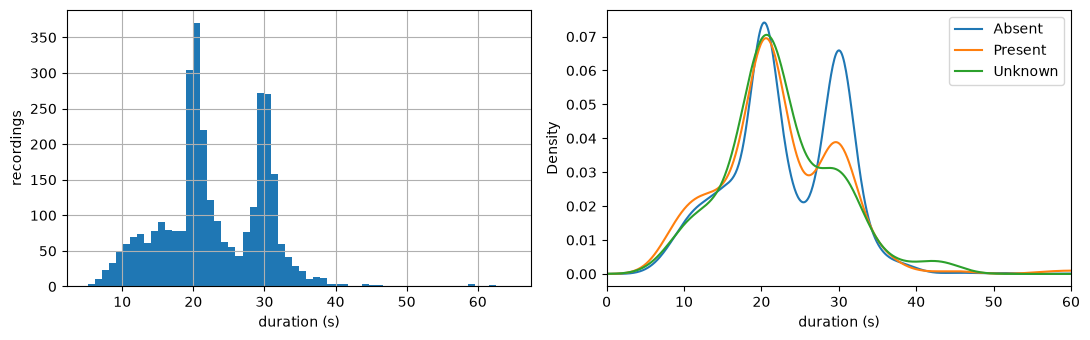

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
rec.duration.hist(bins=60, ax=ax[0]); ax[0].set(xlabel='duration (s)', ylabel='recordings')
rec.groupby('murmur').duration.plot.kde(ax=ax[1], legend=True); ax[1].set(xlabel='duration (s)', xlim=(0, 60))
plt.tight_layout()

## Murmur locations
For *Present* patients the murmur may be audible only at some locations: recording-level labels inherited from
the patient label are noisy. `Murmur locations` lets us build cleaner recording-level labels for training.

In [8]:
present = pat[pat.Murmur == 'Present']
n_rec = present['Recording locations:'].str.split('+').apply(lambda l: len(set(l)))
n_mur = present['Murmur locations'].str.split('+').apply(len)
pd.DataFrame({'recorded locations': n_rec, 'murmur locations': n_mur}).value_counts().sort_index()

recorded locations  murmur locations
1                   1                   10
2                   1                    8
                    2                   19
3                   1                    4
                    2                    7
                    3                   11
4                   1                   12
                    2                   21
                    3                   16
                    4                   70
5                   5                    1
Name: count, dtype: int64

In [9]:
# Recording-level label: murmur audible at this location (only possible for Present patients)
mloc = pat['Murmur locations'].fillna('').str.split('+').apply(set)
rec['murmur_here'] = [m == 'Present' and loc in mloc[p] for p, loc, m in zip(rec.patient_id, rec.location, rec.murmur)]
pr = rec[rec.murmur == 'Present']
silent = pr.groupby('patient_id').murmur_here.mean() < 1
print(f'Present-patient recordings: {len(pr)}, murmur NOT audible in {(~pr.murmur_here).sum()} ({100*(~pr.murmur_here).mean():.0f}%)')
print(f'Present patients with at least one silent recording: {silent.sum()} / {len(silent)}')

Present-patient recordings: 616, murmur NOT audible in 117 (19%)
Present patients with at least one silent recording: 68 / 179


In [10]:
# Most murmurs are faint (grade I/VI) -> subtle signal
pat.loc[pat.Murmur == 'Present', 'Systolic murmur grading'].value_counts()

Systolic murmur grading
I/VI      104
III/VI     46
II/VI      28
Name: count, dtype: int64

Labelling every recording of a *Present* patient as *Present* would mislabel ~19% of those recordings
(and affects 68 of 179 Present patients). Using `Murmur locations` for recording-level targets removes this noise;
the patient prediction then follows from aggregation (e.g. Present if *any* recording is Present).
Most murmurs are grade I/VI (faint), which makes the task harder.

## Segmentation files (.tsv)
Each recording comes with a segmentation: `start, end, state` (0 = unannotated, 1 = S1, 2 = systole, 3 = S2, 4 = diastole).

In [11]:
tsv = pd.read_csv(WAV_DIR / (rec.recording.iloc[0] + '.tsv'), sep='\t', header=None, names=['start', 'end', 'state'])
tsv.head(10)

,start,end,state
0,0.000000,1.146750,0
1,1.146750,1.300191,1
2,1.300191,1.400191,2
3,1.400191,1.540191,3
4,1.540191,1.779916,4
5,1.779916,1.900191,1
6,1.900191,1.980191,2
7,1.980191,2.100191,3
8,2.100191,2.320036,4
9,2.320036,2.460191,1


## Signal quality and the *Unknown* class
*Unknown* means the expert could not decide — we check whether this shows up as poorer recordings, using three proxies:
- **annotated fraction**: share of the recording the segmentation could label as S1/systole/S2/diastole (state > 0);
- **cardiac cycles**: number of S1 segments found;
- **HF energy ratio**: fraction of power above 400 Hz (heart sounds and most murmurs lie below ~400 Hz, so this is mostly noise: crying, speech, friction).

In [12]:
from scipy.signal import welch

def quality(r):
    y, sr = sf.read(r.path)
    t = pd.read_csv(WAV_DIR / (r.recording + '.tsv'), sep='\t', header=None, names=['start', 'end', 'state'])
    f, P = welch(y, sr, nperseg=1024)
    return pd.Series({'annotated': ((t.end - t.start)[t.state > 0]).sum() / (len(y) / sr),
                      'cycles': (t.state == 1).sum(),
                      'hf_ratio': P[f > 400].sum() / P.sum()})

rec = rec.join(rec.apply(quality, axis=1))
rec.groupby('murmur')[['annotated', 'cycles', 'hf_ratio']].median().round(2)

,annotated,cycles,hf_ratio
murmur,,,
Absent,0.52,17.0,0.27
Present,0.60,18.0,0.19
Unknown,0.24,10.0,0.45


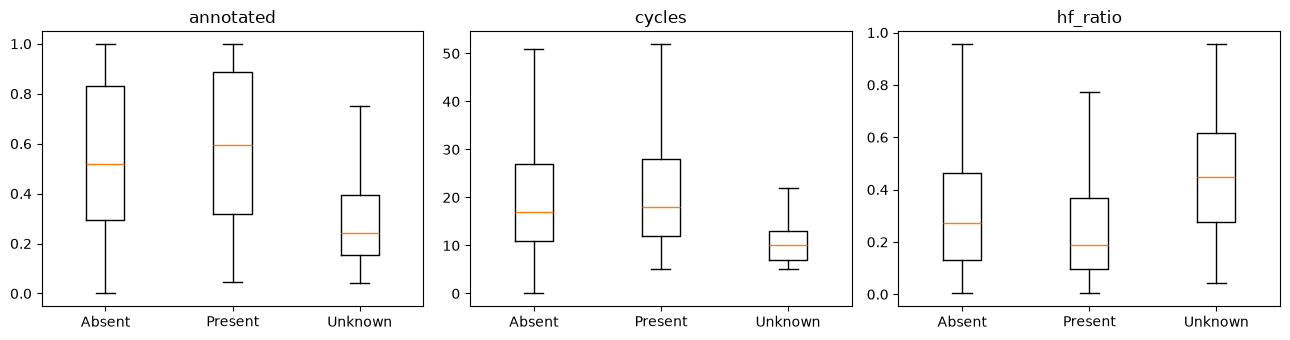

In [13]:
order = ['Absent', 'Present', 'Unknown']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, col in zip(ax, ['annotated', 'cycles', 'hf_ratio']):
    a.boxplot([rec.loc[rec.murmur == m, col] for m in order], tick_labels=order, showfliers=False); a.set_title(col)
plt.tight_layout()

In [14]:
# Unknown rate by age group: infants/neonates are harder to auscultate (crying, movement)
pd.crosstab(pat['Age'].fillna('NA'), pat['Murmur'], normalize='index').round(2)

Murmur,Absent,Present,Unknown
Age,,,
Adolescent,0.74,0.22,0.04
Child,0.75,0.20,0.06
Infant,0.60,0.20,0.20
NA,0.91,0.07,0.03
Neonate,0.67,0.17,0.17


*Unknown* recordings are clearly worse: only ~24% of the signal could be segmented (vs ~55% for the others),
half as many cardiac cycles, and much more energy above 400 Hz. Unknown is also ~3× more frequent in infants (20%)
than in children (6%). So *Unknown* is mainly a **recording-quality** class, not a physiological one: a model must
learn to detect noise, and quality features (or a quality branch) may help.

## Example signals

/home/amarcos20/miniconda3/envs/ml2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


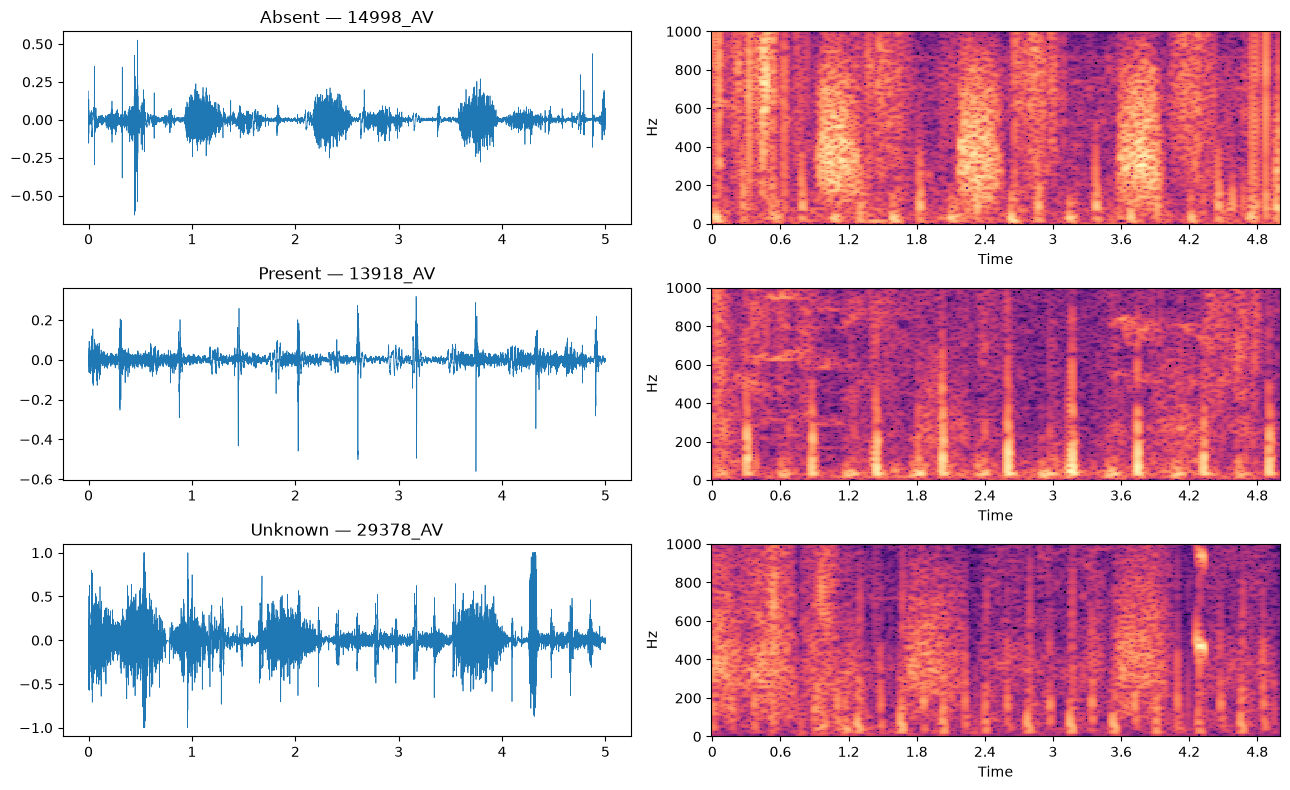

In [15]:
ex = {m: rec[rec.murmur == m].iloc[0] for m in ['Absent', 'Present', 'Unknown']}
fig, axes = plt.subplots(3, 2, figsize=(13, 8))
for (m, r), (a1, a2) in zip(ex.items(), axes):
    y, sr = librosa.load(r.path, sr=None, duration=5)
    a1.plot(np.arange(len(y)) / sr, y, lw=.5); a1.set_title(f'{m} — {r.recording}')
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=64)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=64, x_axis='time', y_axis='linear', ax=a2); a2.set_ylim(0, 1000)
plt.tight_layout()

## Split check

In [16]:
split = load_split()
pd.crosstab(split.fold, split.murmur, margins=True)

murmur,Absent,Present,Unknown,All
fold,,,,
-1,139,36,14,189
0,111,29,11,151
1,112,28,11,151
2,111,28,11,150
3,111,29,11,151
4,111,29,10,150
All,695,179,68,942


## Key findings
1. **Imbalance vs metric.** 74% Absent / 19% Present / 7% Unknown. Always-Absent gives WA = 0.387, always-Present 0.499:
   the metric rewards catching Present (×5) and Unknown (×3), so any useful model must beat ~0.50. → class weights / balanced sampling, thresholds tuned on CV for WA.
2. **Labels are per patient.** ~19% of recordings from Present patients have no audible murmur (68/179 patients affected), and most murmurs are faint (grade I/VI).
   → train on recording-level labels from `Murmur locations`, then aggregate to one prediction per patient.
3. **Unknown ≈ bad recording.** Unknown recordings have far less segmentable signal, fewer cycles and more high-frequency noise, and are concentrated in infants.
   → the model needs to see the noise (don't over-filter), and the Unknown decision can rely on quality cues.
4. **Inputs.** All audio at 4 kHz, 5–64 s (median 21.5 s), mostly 4 locations per patient → fixed-length windows (e.g. 4 s) over each recording; useful band ~25–400 Hz.